In [1]:
import torch
from pathlib import Path
from step.models import XResAttn
import numpy as np

dvc = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
# STEPalpha: Anomalous exponent model
model_kistep = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
             block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
             dim_ff=512, nhead_enc=8, norm=False, linear_layers=[],yrange=(-0.1,2.1)).to('cuda')

model_kistep.load_state_dict(torch.load('xresattn_alpha_2d_varlen_relpolar_yrange_m01_21_big22E2.pth')['model'])


<All keys matched successfully>

In [3]:
def get_angle(from_vec, # T, d=2
              to_vec,   # T, d=2
              ):
    x1, y1 = from_vec[...,0], from_vec[...,1]
    x2, y2 = to_vec[...,0], to_vec[...,1]
    dot = x1*x2 + y1*y2      # Dot product between [x1, y1] and [x2, y2]
    det = x1*y2 - y1*x2      # Determinant (cross2d) # 2.53 micros, njit 256 ns
    return np.arctan2(det, dot)

# We want a relative description of the trajectory
# the modulus of the displacement Delta r, and the change of angle between successive displacements Delta theta 
def cartesian_to_relative_polar(trajs_cart):
    """
    Converts 2D trajectories in cartesian coordinates to
    a relative representation of polar coordinates.

    Parameters:
    - cartesian_coordinates:
    A numpy array of shape (N, T, 2) where
    N is the number of trajectories,
    T is the number of time steps, and
    2 represents the x and y coordinates.

    Returns:
    - An array containing:
    the radius (rho) of each point, and
    the angle from previous direction (theta) of each point in radians.
    """
    # take displacements of the trajectory
    disps_cart = trajs_cart[:, 1:] - trajs_cart[:, :-1]
    # Allocate
    polar_coords = np.zeros_like(disps_cart)

    # Calculate the magnitude (rho) of each point
    polar_coords[...,0] = np.hypot(disps_cart[..., 0], disps_cart[..., 1])  #  dr

    # Calculate the angle (theta) between segments
    v1,v2 = trajs_cart[:,1:-1]-trajs_cart[:,:-2], trajs_cart[:,2:]-trajs_cart[:,1:-1]
    polar_coords[:,1:,1] = get_angle(v1,v2) # d theta

    return polar_coords

In [28]:
from andi_datasets.datasets_challenge import challenge_phenom_dataset


dfs_traj, _, _ = challenge_phenom_dataset(save_data = False, # If to save the files
                                          experiments = [1, 1,1,1,2,2,2,2],
                                                                return_timestep_labs = True,
                                                                num_fovs = 10, # Number of FOVs
                                                                )




  0%|          | 0/8 [00:00<?, ?it/s]

Creating dataset for Exp_0 (single_state).
Creating dataset for Exp_1 (single_state).
Creating dataset for Exp_2 (single_state).
Creating dataset for Exp_3 (single_state).
Creating dataset for Exp_4 (multi_state).
Creating dataset for Exp_5 (multi_state).
Creating dataset for Exp_6 (multi_state).
Creating dataset for Exp_7 (multi_state).


In [29]:
dataset = []
alphas = []
preds = []
mae = []
for df in dfs_traj:    
    mae_exp = []
    # Each df has keys: ['traj_idx', 'frame', 'x', 'y', 'alpha', 'D', 'state']
    for idx in df.traj_idx.unique():
        # Transform the trajectory to relative polar coordinates
        traj_cart = df[df.traj_idx == idx][['x', 'y']].values  # (T, 2)
        traj_polar = torch.tensor(cartesian_to_relative_polar(traj_cart[np.newaxis,...]), dtype=torch.float).to(dvc)    # (T-1, 2)
        dataset.append(traj_polar)
        # Predict the anomalous exponent alpha for this trajectory
        with torch.no_grad():
            traj_pred = model_kistep(traj_polar).flatten().cpu().detach().numpy()
            preds.append(traj_pred)
        # Get the true alpha for this trajectory
        traj_alpha = df[df.traj_idx == idx].alpha.values
        alphas.append(traj_alpha)

        mae_exp.append(np.abs(traj_pred - traj_alpha[:-1]).mean())
    mae.append(mae_exp)

In [31]:
len(mae)

80

In [32]:
means = [np.mean(m) for m in mae]
np.mean(means[:40]), np.mean(means[40:])

(0.24554394760585802, 0.19124234353184263)

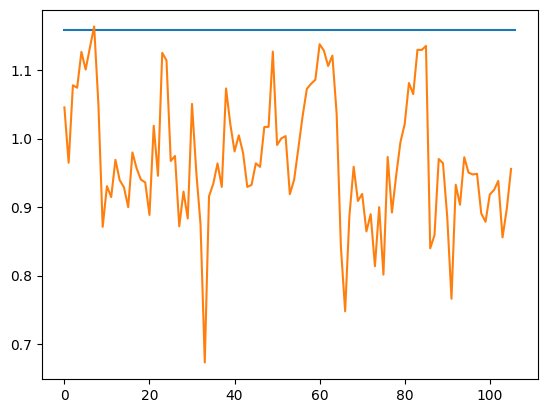

In [ ]:
import matplotlib.pyplot as plt

idx = 15

plt.plot(alphas[idx])
plt.plot(model_kistep(dataset[idx]).flatten().cpu().detach().numpy())

In [45]:
alphas[0]

array([1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100875,
       1.12100875, 1.12100875, 1.12100875, 1.12100875, 1.12100

In [34]:
learn_alpha.model(dataset[-1]).flatten()

tensor([1.2182, 1.2145, 1.2116, 1.2109, 1.2146, 1.2108, 1.2053, 1.2042, 1.2102,
        1.2090, 1.2079, 1.2036, 1.2011, 1.2026, 1.2069, 1.2072, 1.2151, 1.2140,
        1.2192, 1.2278, 1.2290, 1.2226, 1.2384, 1.2446, 1.2410, 1.2207, 1.2075,
        1.2079, 1.2074, 1.2043, 1.2043, 1.2069, 1.2005, 1.2060, 1.2052, 1.2045,
        1.2072, 1.2059, 1.2086, 1.2070, 1.2061, 1.2072, 1.2056, 1.2052, 1.2063,
        1.2096, 0.6236, 0.5517, 0.5444, 0.5428, 0.5471, 0.5433, 0.5359, 0.5443,
        0.5437, 0.5394, 0.5359, 0.5372, 0.5378, 0.5373, 0.5376, 0.5342, 0.5392,
        0.5448, 0.5419, 0.5441, 0.5382, 0.5368, 0.5369, 0.5356, 0.5383, 0.5343,
        0.5356, 0.5424, 0.5399, 0.5412, 0.5419, 0.5333, 0.5353, 0.5345, 0.5379,
        0.5442, 0.5434, 0.5404, 0.5395, 0.5374, 0.5371, 0.5434, 0.5467, 0.5409,
        0.5425, 0.5477, 0.5458, 0.5446, 0.5433, 0.5385, 0.5397, 0.5386, 0.5433,
        0.5438, 0.5406, 0.5455, 0.5455, 0.5405, 0.5400, 0.5338, 0.5339, 0.5383,
        0.5401, 0.5393, 0.5336, 0.5613, 